# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: EL SIGMA MAYOR

# Integrantes
* Katerina Lichtensztenin
* Lucia Murillo
* Manel Montalat
* Sofia Cácharo Hernáez

### Ejercicio 1 - DLT ecuaciones formales

A partir de los datos compartidos en calib/3d armar
el sistema de la ecuación 6. Contestar las siguientes preguntas:

**Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?**

***Sobre la matriz Q:***

- Solución no única a menos de un factor de escala: Queremos que todas las soluciones de $Qm=0$ sean múltiplos de un mismo vector (una recta de soluciones). 
    Esto significa que el núcleo de Q tiene dimensión 1: $$\dim(\operatorname{Nu}(Q))=1$$

- Qm = 0, es decir, el núcleo de Q debe tener dimension 1 (para que sea una recta). Por el teorema de rango y nulidad: $$Rg(Q) = 12 - dim(Nu(Q)) = 11$$

- Como cada punto de Q ocupa 2 filas, necesitamos minimo 6 puntos para que tenga rango 12 . Los puntos no pueden ser coplanares: son necesarios 2 planos mínimo para que no se anulen columnas, es decir, mínimo 2 puntos en otro plano (4 en uno y 2 en otro es lo mínimo)

- Q se arma con la info de detected corners (u, v) y pw corners (U, V W).
    Para m hacemos núcleo de Q usando la función armada del labo (no tiene restricciones de tamaño)

**Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.**



$$
\min_{\|m\|=1} \|Qm\|^2
= \min_{\|m\|=1} (Qm)^T Qm
= \min_{\|m\|=1} m^T Q^T Qm
$$

$$
= \lambda_{12} = \sigma_{12}^2
$$

### Preliminares

- Sea $\{v_1, \dots, v_{12}\}$ un conjunto ortonormal:

  $$\langle v_i, v_{12} \rangle = 0 \quad \forall i \neq 12$$

  $$\langle v_{12}, v_{12} \rangle = 1$$

- Sea $U$ ortonormal:

  $$U^T = U^{-1} \qquad \text{y} \qquad U^T U = U^{-1}U = \mathrm{Id}$$

- Sea $V$ ortonormal cuadrada:

  $$V^T V = VV^T = \mathrm{Id}$$

- Y teniendo en cuenta que toda norma es positiva: $\|m\|>0$ 

### Demostración

Sea $\tilde{Q} = Q^T Q$. Entonces, $\tilde{Q}$ es simétrica y semidefinida positiva.

### Simetría

$$
\begin{aligned}
\tilde{Q}^T
&= (Q^T Q)^T \\
&= Q^T (Q^T)^T \\
&= Q^T Q \\
&= \tilde{Q}
\end{aligned}
$$

### Semidefinida positiva

Sea $x \in \mathbb{R}^{12}$:

$$
\begin{aligned}
x^T \tilde{Q}x
&= x^T Q^T Qx \\
&= (Qx)^T Qx \\
&= \|Qx\|^2 \geq 0
\end{aligned}
$$

Con $Q \in \mathbb{R}^{2n \times 12}$.

Por lo tanto, sus autovalores cumplen:

$$\lambda_i \geq 0 \quad \forall i$$

En efecto, si $\tilde{Q}v = \lambda v$, con $v \neq 0$, entonces:

$$
v^T \tilde{Q}v = \lambda \|v\|^2 \geq 0
$$

y, por lo tanto, $\lambda \geq 0$.

---

### Descomposición SVD ordenada

Consideramos los autovalores ordenados:

$$
\lambda_1 \geq \lambda_2 \geq \dots \geq \lambda_{12} \geq 0
$$

La descomposición SVD de $Q$ es:

$$Q = U \Sigma V^T$$

con:

- $Q \in \mathbb{R}^{2n \times 12}$.
- $U \in \mathbb{R}^{2n \times 2n}$ ortonormal.
- $\Sigma \in \mathbb{R}^{2n \times 12}$ diagonal no negativa.
- $V \in \mathbb{R}^{12 \times 12}$ ortonormal.

Además:

$$Q^T \in \mathbb{R}^{12 \times 2n}, \qquad \tilde{Q} \in \mathbb{R}^{12 \times 12}$$

La matriz $\Sigma$ tiene la siguiente forma:

$$
\Sigma =
\begin{pmatrix}
\sqrt{\lambda_1} & & \\
& \ddots & \\
& & \sqrt{\lambda_{12}} \\
& & 0
\end{pmatrix}
$$

Con los primeros 12 elementos en la diagonal y ceros debajo.

Por otra parte:

$$
V^T =
\begin{pmatrix}
v_1^T \\
\vdots \\
v_{12}^T
\end{pmatrix}
$$

Entonces:

$$
\begin{aligned}
\tilde{Q}
&= Q^T Q \\
&= (U\Sigma V^T)^T(U\Sigma V^T) \\
&= V\Sigma^T U^T U\Sigma V^T \\
&= V\Sigma^T\Sigma V^T \\
&= V\Lambda V^T
\end{aligned}
$$

Donde:

$$\Lambda = \Sigma^T\Sigma$$

Observamos que:

$$
\Sigma \in \mathbb{R}^{2n \times 12}
\Rightarrow
\Sigma^T \in \mathbb{R}^{12 \times 2n}
$$

Por lo tanto:

$$\Sigma^T\Sigma \in \mathbb{R}^{12 \times 12}$$

En particular:

$$
\begin{pmatrix}
\sqrt{\lambda_1} & 0 & \dots & 0 \\
0 & \sqrt{\lambda_2} & \dots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \dots & \sqrt{\lambda_{12}}
\end{pmatrix}
\begin{pmatrix}
\sqrt{\lambda_1} & 0 & \dots & 0 \\
0 & \sqrt{\lambda_2} & \dots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \dots & \sqrt{\lambda_{12}}
\end{pmatrix}
$$

$$
=
\begin{pmatrix}
\lambda_1 & 0 & \dots & 0 \\
0 & \lambda_2 & \dots & 0 \\
\vdots & \vdots & \ddots & \vdots \\
0 & 0 & \dots & \lambda_{12}
\end{pmatrix}
= \Lambda
$$

---

### Retomando...

$$
\begin{aligned}
\min_{\|m\|=1} m^T Q^T Qm
&= \min_{\|m\|=1} m^T \tilde{Q}m \\
&= \min_{\|m\|=1} m^T V\Lambda V^T m
\end{aligned}
$$

Sea $y = V^T m$. Como $\|m\|=1$ y $V$ es ortogonal:

$$
\begin{aligned}
\|y\|^2
&= \|V^T m\|^2 \\
&= (V^T m)^T V^T m \\
&= m^T VV^T m \\
&= m^T m \\
&= \|m\|^2 = 1
\end{aligned}
$$

Por lo tanto:

$$\|y\|=1$$

Además:

$$
\begin{aligned}
m^T\tilde{Q}m
&= m^T V\Lambda V^T m \\
&= (V^T m)^T\Lambda V^T m \\
&= y^T\Lambda y
\end{aligned}
$$

Desarrollando:

$$
\begin{aligned}
y^T\Lambda y
&=
y^T
\begin{pmatrix}
\lambda_1 y_1 \\
\vdots \\
\lambda_{12}y_{12}
\end{pmatrix} \\
&= \sum_{i=1}^{12} y_i(\lambda_i y_i) \\
&= \sum_{i=1}^{12}\lambda_i y_i^2
\end{aligned}
$$

### Cota

Como:

$$
\lambda_i \geq \lambda_{12}
\quad \forall i
\qquad \land \qquad
y_i^2 \geq 0
$$

Se tiene:

$$
\begin{aligned}
\sum_{i=1}^{12}\lambda_i y_i^2
&\geq \sum_{i=1}^{12}\lambda_{12}y_i^2 \\
&= \lambda_{12}\sum_{i=1}^{12}y_i^2 \\
&= \lambda_{12}\|y\|^2 \\
&= \lambda_{12}\cdot 1 \\
&= \lambda_{12}
\end{aligned}
$$

Por lo tanto:

$$
m^T\tilde{Q}m \geq \lambda_{12}
\qquad
\forall m \text{ tal que } \|m\|=1
$$

### Alcance

Como las columnas de $V$ son ortonormales:

$$V^T v_{12} = e_{12}$$

Entonces, tomando $y=e_{12}$:

$$
y^T\Lambda y
= \sum_{i=1}^{12}\lambda_i y_i^2
= 0+\dots+\lambda_{12}\cdot 1
= \lambda_{12}
$$

Por lo tanto, tomando $m=v_{12}$ se alcanza la cota:

$$
v_{12}^T\tilde{Q}v_{12}
= y^T\Lambda y
= \lambda_{12}
$$

---

### Conclusión

Por la cota:

$$
m^T\tilde{Q}m \geq \lambda_{12}
\qquad
\forall m \text{ tal que } \|m\|=1
$$

Y por el alcance en $m=v_{12}$:

$$m^T\tilde{Q}m = \lambda_{12}$$

Por lo tanto, el mínimo vale:

$$
\boxed{
\min_{\|m\|=1}\|Qm\|^2
= \lambda_{12}
= \sigma_{12}^2
}
$$

Y se alcanza en:

$$\boxed{m=v_{12}}$$

Como $V$ es ortonormal, se cumple:

$$\|v_{12}\|=1$$

### Ejercicio 2 - Calibración con puntos 3D

a) Implementar la función obtenerQ3d(imgPts, objPts) que devuelve la matriz Q a partir
de la ecuación 6.

b) A partir de lo resuelto en el Ejercicio 1 b), implementar la función resolverDLT3D(Q),
que a partir de $Q$ encuentra la matriz de proyección $M$.

c) Una vez recuperada M, se la descompone en la matriz de parámetros intrínsecos K,
la matriz de rotación R y el vector de traslación t, imponiendo que R sea ortonormal
($RRT = I$). Para ello, implementar la función devolverMatricesCalibracion3d(M),
que devuelva R, t y K.

d) Agregar a la función devolverMatricesCalibracion3d un parámetro opcional que permita imponer que $αu = αv y/o K12 = 0$.

In [1]:
import numpy as np
import os

carpeta = os.path.join("calib", "3d")
coord_pix_fotos = np.loadtxt(os.path.join(carpeta, "detected_corners.txt"))
coord_reales_puntos = np.loadtxt(os.path.join(carpeta, "p_W_corners.txt"), delimiter=",")

from alc import obtenerQ3d, resolverDLT3D, devolverMatricesCalibracion3d

Q = obtenerQ3d(coord_pix_fotos[0],coord_reales_puntos)
print(f"Q = {Q}")

M = resolverDLT3D(Q)
print(f"\nM = {M}")
# el signo de m depende del vector aleatorio que se genera en metpot2k, dentro de diagRH, eso afecta el signo de M y luego su determinante --> impacta en determinante de R 

R, t, K = devolverMatricesCalibracion3d(M)
print(f"\nR: {R}")
Rt = np.zeros((3,4))
Rt[:, :3] = R
Rt[:, 3] = t
print(f"\nLa matriz [R t] es {Rt}")
print(f"con R = {R}")
print(f"y t = {t}")

Q = [[ 0.0000000e+00  8.0000000e+00  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -0.0000000e+00 -1.4920000e+03 -0.0000000e+00 -1.8650000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   0.0000000e+00  8.0000000e+00  0.0000000e+00  1.0000000e+00
  -0.0000000e+00 -1.5000000e+03 -0.0000000e+00 -1.8750000e+02]
 [ 1.0400000e+01  8.0000000e+00  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -2.7508000e+03 -2.1160000e+03 -0.0000000e+00 -2.6450000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   1.0400000e+01  8.0000000e+00  0.0000000e+00  1.0000000e+00
  -1.7316000e+03 -1.3320000e+03 -0.0000000e+00 -1.6650000e+02]
 [ 0.0000000e+00  2.1500000e+01  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -0.0000000e+00 -4.6977500e+03 -0.0000000e+00 -2.1850000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00

### Ejercicio 3 - Calibración con puntos coplanares

**¿Qué rango debe tener $Q ∈ R2n×9$ para asegurar una solución única de $H$ a menos de un factor de escala?**

Como $W=0$ para todos los puntos, ahora $Q$ tiene 3 columnas que se anulan. Por lo tanto:

$$
Q\in\mathbb{R}^{2n\times9}
$$

Nuevamente, queremos que $\dim(\operatorname{Nu}(Q))=1$, para que la solución sea única salvo un factor de escala.

Aplicando el teorema de rango y nulidad:

$$
\operatorname{Rg}(Q)=9-\dim(\operatorname{Nu}(Q))=8
$$

**Cantidad mínima de puntos**

Necesitamos 4 puntos, ya que cada uno aporta 2 filas a $Q$:

$$
2n=8 \Rightarrow n=4
$$

Esto significa que necesitamos 8 filas linealmente independientes.

**Condición geométrica**

Los puntos no pueden tener tres puntos colineales, es decir, no debe existir una recta que contenga 3 puntos a la vez.

**Implementar la función obtenerQ2d(imgPts, objPts) que devuelve la matriz Q a partir de la ecuación 11.**

**Implementar la función armarA(Hlst) que recibe una lista de matrices Hj correspondientes a las N capturas de las miras, obtenidas a partir de la resolución del sistema planteado en la ecuación 11.**

**Implementar calcularMatrizK2D(A) que recibe la matriz A y calcula la matriz K.**

**Implementar obtenerPose2D(Hj, K) que devuelve la pose de la vista j como Rj y tj a partir de la matriz K y la Hj correspondiente**

In [2]:
## PROBLEMA: A VECES A TIENE FILAS NAN Y FALLA

carpeta = os.path.join("calib", "coplanar")
coord_pix_ajedrez = np.loadtxt(os.path.join(carpeta, "img_pts.txt"))
coord_reales_ajedrez = np.loadtxt(os.path.join(carpeta, "obj_pts.txt"))

from alc import armar_Hs, armarA, calcularMatrizK2D, obtenerPose2D

# Armamos la lista de Homografias a partir de los puntos de los tableros
Hlst_ajedrez = armar_Hs(coord_pix_ajedrez, coord_reales_ajedrez)
A = armarA(Hlst_ajedrez)
print(f"\nLa matriz A es {A}")
K_ajedrez = calcularMatrizK2D(A) 
Rj, tj = obtenerPose2D(Hlst_ajedrez[0], K_ajedrez)

print(f"\nLa matriz de calibracion K es {K_ajedrez}")
print(f"\nLa matriz de rotacion R es {Rj}")
print(f"\nEl vector de traslacion t es {tj}")


La matriz A es [[-3.69128687e-02  1.88838133e+00  4.33067222e-02 -2.22834909e-05
   6.84763183e-05 -7.64164387e-10]
 [ 1.90253308e+00  1.60538126e-01 -1.87430919e+00  1.38123937e-04
   4.47487126e-05  2.30525902e-09]
 [ 4.13404619e-01  1.71536341e+00 -3.93002138e-01  1.54161196e-05
   7.43595629e-05 -6.29321962e-11]
 [ 1.72232100e+00 -1.61259449e+00 -1.70829479e+00  1.49655992e-04
  -2.93751061e-05  3.05257059e-09]
 [ 1.16247347e-01  1.99136872e+00 -8.43184282e-02  1.22413214e-05
   1.05594405e-04  3.22249208e-10]
 [ 2.01195177e+00 -4.00444920e-01 -1.97055794e+00  2.13374267e-04
  -2.10621408e-05  5.65726131e-09]
 [ 1.01441490e-01  2.07227432e+00 -7.30295394e-03  1.42947627e-04
   1.04617004e-04  6.98797864e-09]
 [ 2.05196676e+00 -2.18923320e-01 -2.08838777e+00  1.95024815e-04
  -2.78440725e-04 -3.94249590e-09]
 [-1.68259891e-01  2.01795746e+00  1.90927949e-01 -6.91506504e-05
   1.87598380e-04 -5.03955761e-09]
 [ 2.10536631e+00  7.20833855e-01 -1.93351343e+00  3.92830329e-04
   1.3983

### Ejercicio 4 - Fútbol

In [3]:
from alc import estimar_H, inversa, multiplicarAx
puntos_pixeles = np.loadtxt("puntos_gol_enzo.txt")

imgPts_enzo = np.array(puntos_pixeles, dtype=float).reshape(-1)
objPts_enzo =np.array([(24.84,0),(24.84,5.5),(43.16,0),(43.16,5.5),(34,11),(26.69,16.5),(41.31,16.5),(30.34,0),(37.66,0)])

H_enzo = estimar_H(imgPts_enzo, objPts_enzo)

inversa_H_enzo = inversa(H_enzo)

punto_pie_enzo = np.loadtxt("punto_enzo.txt")
pie_enzo = np.array((punto_pie_enzo[0], punto_pie_enzo[1], 1)) #agrego el 1 para las dimensiones

posicion_pie_en_imagen = multiplicarAx(inversa_H_enzo, pie_enzo) # = (U,V,W)
posicion_pie_en_imagen = posicion_pie_en_imagen/posicion_pie_en_imagen[2] #normalizamos para que la tercera coordenada sea 1
print(f"Posición del pie en la imagen: {posicion_pie_en_imagen}")

distancia_pie_a_arco = posicion_pie_en_imagen[1] #coordenada V 
print(f"La distancia del pie al arco es: {round(distancia_pie_a_arco,4)} metros")

Posición del pie en la imagen: [39.84082698 22.07663812  1.        ]
La distancia del pie al arco es: 22.0766 metros


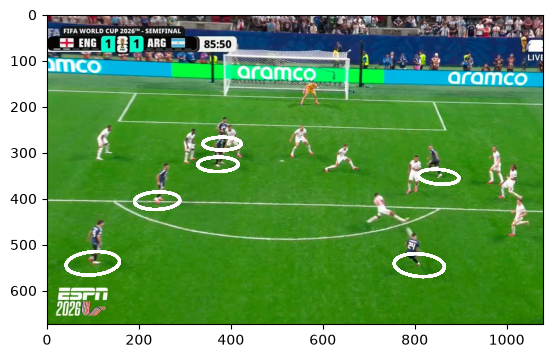

In [4]:
import cv2
import matplotlib.pyplot as plt
from alc import circulo
pies_jugadores = np.loadtxt("pies_jugadores_arg.txt")
img = cv2.imread(os.path.join("futbol", "test-gol-enzo.png"))

fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)) #para que no sean avatares
for coord_pie_pixel in pies_jugadores:
    coord_pie_pixel = np.array((coord_pie_pixel[0], coord_pie_pixel[1],1)) #agrego el 1 para las dimensiones
    posicion_pie_mundo = multiplicarAx(inversa_H_enzo, coord_pie_pixel) # = (U,V,1)
    posicion_pie_mundo = posicion_pie_mundo/posicion_pie_mundo[2] #normalizamos para que la tercera coordenada sea 1
    U = posicion_pie_mundo[0]
    V = posicion_pie_mundo[1]
    U_c, V_c = circulo((U,V), 1.0, 100)

    u_ci, v_ci = [],[]
    for U_circulo,V_circulo in zip(U_c,V_c): #chequear este zip
        punto_circulo_jugador = multiplicarAx(H_enzo,np.array([U_circulo,V_circulo,1]))
        u_ci.append(punto_circulo_jugador[0]/punto_circulo_jugador[2])
        v_ci.append(punto_circulo_jugador[1]/punto_circulo_jugador[2])
        ax.plot(u_ci,v_ci,color="white", linewidth=2)
        #ax.fill(u_ci, v_ci, facecolor=(1, 1, 1, 0.3), edgecolor="none", opacity=.3)   # relleno pero NO traslúcido, si lo permiten y lo piden, ver si existe polygon
plt.show()

Posición del defensor en la imagen: [90.62826276 16.68612626  1.        ]


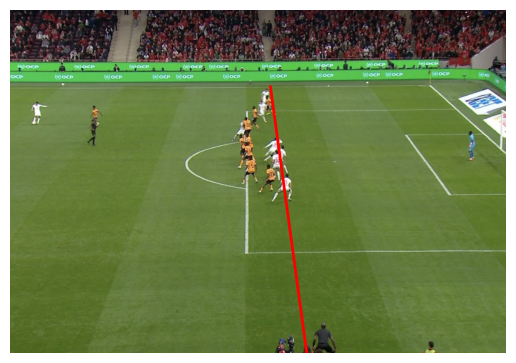

In [5]:
from alc import estimar_H, inversa, multiplicarAx
#archivo = "puntos_offside.txt"
puntos_pixeles_offside = np.loadtxt("puntos_offside.txt")
#puntos_pixeles_offside = [(736, 317), (732, 559), (734, 757), (1304, 235), (1230, 390), (1365, 578), (1010, 473)]
imgPts_offside = np.array(puntos_pixeles_offside, dtype=float).reshape(-1)
objPts_offside =np.array([(88.5,13.84),(88.5,41.31),(88.5,54.16),(105,0),(99.5,24.84),(99.5,43.16),(94,34)])

H_offside = estimar_H(imgPts_offside, objPts_offside)
inversa_H_off = inversa(H_offside)

posicion_pie_defensor = np.loadtxt("pie_defensor.txt")

pie_defensor = np.array([posicion_pie_defensor[0], posicion_pie_defensor[1], 1]) #agrego el 1 para las dimensiones
posicion_defensor_en_imagen = multiplicarAx(inversa_H_off, pie_defensor) # = (U,V,W)
posicion_defensor_en_imagen = posicion_defensor_en_imagen/posicion_defensor_en_imagen[2] #normalizamos para que la tercera coordenada sea 1, (U,V,1)

print(f"Posición del defensor en la imagen: {posicion_defensor_en_imagen}")

distancia_defensor_a_arco = posicion_defensor_en_imagen[0] #coordenada V 

#definimos dos puntos para trazar la recta en la imagen
P1_estadio = (posicion_defensor_en_imagen[0],0)
P2_estadio = (posicion_defensor_en_imagen[0],68)
p1_imagen = multiplicarAx(H_offside,np.array([P1_estadio[0],P1_estadio[1],1]))
p1_imagen = p1_imagen / p1_imagen[2]
p2_imagen = multiplicarAx(H_offside,np.array([P2_estadio[0],P2_estadio[1],1]))
p2_imagen = p2_imagen / p2_imagen[2]

#graficamos
img_off = cv2.imread(os.path.join("futbol", "test-fuera-de-juego.png"))
alto, ancho, _ = img_off.shape
fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(img_off, cv2.COLOR_BGR2RGB)) #para que no sean avatares
ax.plot([p1_imagen[0], p2_imagen[0]], [p1_imagen[1], p2_imagen[1]], color="red", linewidth=2)   

ax.axis("off") # sacamos los ejes y números

ax.set_xlim(0, ancho) # sacamos la franja blanca
ax.set_ylim(alto, 0)  # Invertido para mantener el origen arriba a la izquierda

plt.show()

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

In [6]:
import os
import numpy as np
from alc import calcularMatrizK2D, armar_Hs, armarA, recuperarPares

obj_points_salguero, img_points_salguero = recuperarPares(os.path.join("salguero", "world_img_pts.csv"))
#forzamos Z=0, despreciando la diferencia de altura entre los puntos del mundo real, para que sea un problema 2D
obj_pts_salguero_2d_vista1 = obj_points_salguero[0][:, :2]  # Tomamos solo las coordenadas X e Y
# Aplanamos cada una de las 4 vistas a 1D (u1, v1, u2, v2, ...) y las apilamos
img_points_salguero_vistas = np.array([vista.reshape(-1) for vista in img_points_salguero], dtype=np.float32)

Hlst_salguero = armar_Hs(img_points_salguero_vistas, obj_pts_salguero_2d_vista1)
A_salguero = armarA(Hlst_salguero)
K_salguero = calcularMatrizK2D(A_salguero)
print(K_salguero)

salguero\world_img_pts.csv
[[2.80314192e+03 1.27839423e+03 3.34841979e+02]
 [0.00000000e+00 2.30982194e+02 2.13278771e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


Homografía:
[[-1.09929427e-01 -6.30374504e-02 -7.03154295e-01]
 [ 1.43379161e-03 -1.05156377e-02 -6.99572246e-01]
 [ 9.18368530e-06 -5.74392725e-05 -1.36862954e-03]]


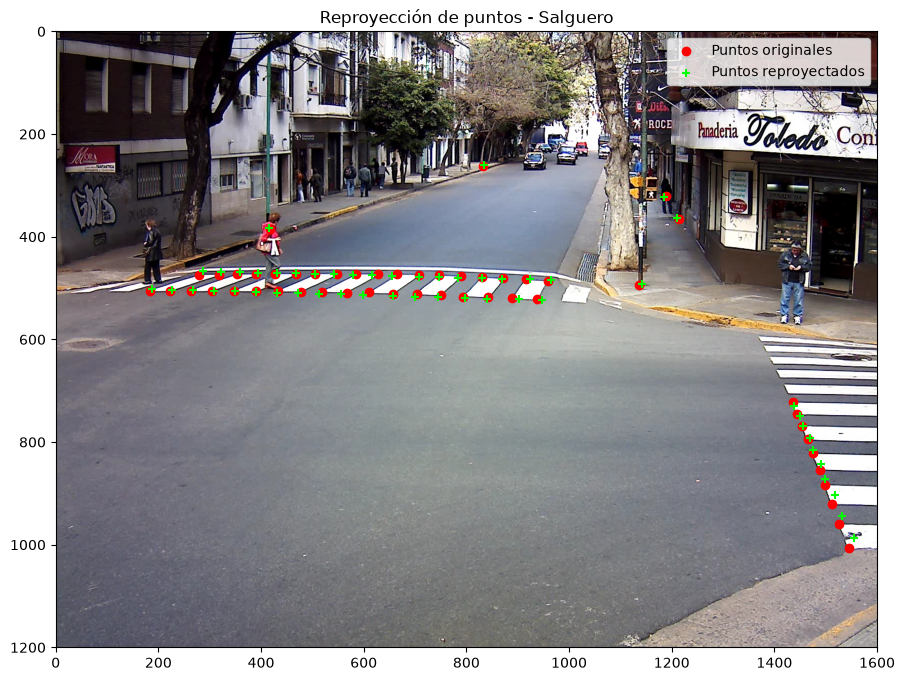

In [7]:
from alc import obtenerQ2d, multiplicarMatrices, diagRH, multiplicarAx
# Cargar correspondencias
salguero_pts_img = np.loadtxt(os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt"))

# Separar coordenadas del mundo y de la imagen
salguero_pts = salguero_pts_img[1:3, :].T
salguero_img = salguero_pts_img[4:6, :].T

# Aplanar coordenadas de imagen
salguero_img_fila = salguero_img.flatten()

# Construir matriz Q
Q_img_salguero = obtenerQ2d(salguero_img_fila,salguero_pts)

# Resolver DLT
QtQ = multiplicarMatrices(Q_img_salguero.T,Q_img_salguero)

S_img_salguero, D_img_salguero = diagRH(QtQ, 1e-8)

# Obtener autovector del menor autovalor
h_img_salguero = S_img_salguero[:, -1]

# Reconstruir homografía (sin normalizar)
H_img_salguero = h_img_salguero.reshape(3, 3)

print("Homografía:")
print(H_img_salguero)

# Agregar coordenada homogénea a los puntos del mundo
salguero_pts_h = np.hstack((salguero_pts,np.ones((len(salguero_pts), 1))))

# Reproyectar puntos del mundo a la imagen
pix_salguero_img = []

for punto in salguero_pts_h:

    res = multiplicarAx(H_img_salguero, punto)

    # Deshomogeneizar
    res = res / res[2]

    # Guardar coordenadas u,v
    pixel = res[:2]

    pix_salguero_img.append(pixel)

pix_salguero_img = np.array(pix_salguero_img)

# Cargar imagen
img = cv2.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# Graficar puntos originales y reproyectados
plt.figure(figsize=(14, 8))
plt.imshow(img)

plt.scatter(
    salguero_img[:, 0],
    salguero_img[:, 1],
    color="red",
    marker="o",
    label="Puntos originales"
)

plt.scatter(
    pix_salguero_img[:, 0],
    pix_salguero_img[:, 1],
    color="lime",
    marker="+",
    label="Puntos reproyectados"
)

plt.legend()
plt.xlim(0, img.shape[1])
plt.ylim(img.shape[0], 0)
plt.title("Reproyección de puntos - Salguero")
plt.show()


### Ejercicio 6 - Aterrizaje suave

---